# Paper two: interactive notes

Working notes for the second paper. Every result here is computed from the `physics` package (symbolic functions in `physics.symbolic.paper2`, numerical solvers in `physics.functions`), with symbols from `physics/symbolic/variables.py`. The prose versions live in `../sections/`; the running to-do list is `../todo.md`.

**Required geometry (since 2026-11-26): co-expansion along the flow** (section 0); sections 1–11 record the earlier isotropic version.

**Earlier geometry: self-consistent co-expansion.** All matter co-expands with the change in $y$: every material length scales by the local Lorentz factor $\gamma$ of the inclination into $y$, and every clock runs at $1/\gamma$. Bodies move along this geometry (co-motion along $y$), and that universality is the origin of the equivalence principle.

Contents
0. Current geometry: co-expansion along the flow (2026-11-26)
1. Co-expansion and the self-consistent Lorentz factor
2. The exact metric and where it differs from GR
3. The absolute frame: outward flow and synchronization
4. Paths without time: light, orbits, deflection
5. The field equation
6. The action, the source inside matter, and the fall
7. Self-gravitating bodies: the strong equivalence principle
8. Several masses
9. Compact objects (leading-order source)
10. Neutron-star interiors and the strong-field equivalence principle
11. Time-dependent equations under option A
12. All consistency checks
13. Open items

## Where we are (2026-11-26)

**The geometry changed on 2026-11-26: co-expansion along the flow.** Matter at rest relative to a mass co-expands as a body moving through the outward flow does in special relativity:
* lengths **along** the flow scale by $\gamma$;
* clocks run at $1/\gamma$;
* lengths **across** the flow are unchanged.

The flow is still set by the measured radius, $\beta^2=2GM/c^2R$, and the field equations are Einstein's, written on the slices of absolute time. Every interval is a sum of squares, signature $(+,+,+,+)$. Section 0 shows the result:
* the exterior is exactly Schwarzschild;
* the flow rule is the Hamiltonian constraint on flat absolute slices;
* the inclined space is Flamm's paraboloid.

So every test of GR passes, including PSR J0337+1715. Paper one (`../../iop/main.tex`) has been rewritten to this geometry; the previous version is `iop/main_v7_isotropic_coexpansion.tex`.

**Sections 1–11 are history.** They develop co-expansion in *every* direction, $\gamma=u+\sqrt{1+u^2}$. That version departs from GR at second order, and its neutron stars violate the strong equivalence principle by about 4% (section 10), which is excluded. The results stay here because they explain why the direction of co-expansion matters.

| | status |
|---|---|
| Co-expansion along the flow; exact Schwarzschild exterior (section 0) | **current**, 15/15 checks |
| Flow rule = Hamiltonian constraint on flat slices; Hubble flow the same equation | done |
| Positive-definite (+,+,+,+) form of every interval | done |
| **A1:** spherical dust gravity = Newtonian zero-energy flow of space (section 0b) | done, derived (not imported) |
| **A2:** field equation for $y$: bending into $y$ = density (section 0c) | done; two-mass solution open |
| **B:** absolute time inside matter, $d\ln N/dR\propto R B(\epsilon+p)$ (section 0d) | done; neutron star $N_c\approx0.67$ |
| Strong equivalence principle, binary pulsars, GW speed | pass (field equations are Einstein's) |
| Slicing of absolute time for several bodies (how bodies' "now" joins) | open |
| A dynamics of $y$ of its own (beyond the inclination of space) | open |
| Sections 1–11: isotropic co-expansion | superseded (history) |

In [23]:
import sympy as smp
import numpy as np
import matplotlib.pyplot as plt

import physics.notebook as nb
from physics.symbolic import paper2 as p2
import physics.functions as pf
from physics.symbolic.variables import (
    G, M, R, a, c, m, r, v, x, y, z, Phi,
    compactness, gamma, psi_field, E_orbit, L, u_inverse, E_binding, T_kinetic,
)

smp.init_printing()
u = compactness  # u = G M / (c^2 r), r the absolute radius


def show(label, *exprs, sep=r"\qquad"):
    """Render a markdown label followed by sympy expressions as display LaTeX."""
    body = sep.join(smp.latex(e) if isinstance(e, smp.Basic) or hasattr(e, "_sympy_") else str(e) for e in exprs)
    nb.printMarkdown(f"{label} $\\displaystyle {body}$" if exprs else label)


def show_report(rep):
    """Render a ConsistencyReport as a markdown table."""
    passed = sum(1 for _, ok, _ in rep.rows if ok)
    rows = "\n".join(f"| {'✅' if ok else '❌'} | {name} |" for name, ok, _ in rep.rows)
    nb.printMarkdown(f"**{rep.title}**: {passed}/{len(rep.rows)} checks pass\n\n| | check |\n|---|---|\n{rows}")

## 0. Current geometry: co-expansion along the flow

Static observer and absolute frame, each written as a sum of squares:
$$\frac{c^2dt^2}{\gamma^2}=c^2d\tau^2+\gamma^2dR^2+R^2d\Omega^2,\qquad c^2dT^2=c^2d\tau^2+|d\mathbf x-\mathbf W\,dT|^2,\quad \mathbf W=\beta c\,\hat{\mathbf R},\quad \gamma=\frac{1}{\sqrt{1-2GM/c^2R}} .$$
The absolute slices are flat, and the absolute radius equals the measured radius. Moving $c^2d\tau^2$ to the other side gives Schwarzschild in its static and outward Painlevé–Gullstrand charts.
* **Flow rule = Hamiltonian constraint:** on flat slices with unit lapse, $(R\beta^2)'=8\pi G\rho R^2/c^2$, i.e. $\beta^2=2Gm(R)/c^2R$. Outside matter this is the flow rule; for the Hubble flow it is the Friedmann equation.
* **Inclined space:** $dy/dR=\beta\gamma$, so $y=2\sqrt{2M(R-2M)}$, Flamm's paraboloid. The synchronization offset is $c(dT-dt)=-\gamma\,dy$.
* **Co-scaling:** the exponents (clock, along, across) are $(-1,+1,0)$, the same as special relativity.
* **Earth:** for a uniform body the proper radius exceeds the measured radius by $GM/3c^2\approx1.5$ mm.

In [ ]:
Rq_, Mq_ = (smp.Symbol(s_.name, positive=True) for s_ in (R, M))
show(r"Flow Lorentz factor $\gamma =$", p2.gamma_flow(), r",\qquad \beta =", p2.beta_flow(), sep=" ")
show(r"Static form (Lorentzian, to compare with GR): $g =$", p2.static_metric_lorentzian(Rq_, Mq_, G=1, c=1))
show(r"Flamm height $y(R) =$", p2.flamm_height(Rq_, Mq_, G=1, c=1), r",\qquad dy/dR - \beta\gamma =",
     smp.simplify(smp.diff(p2.flamm_height(Rq_, Mq_, G=1, c=1), Rq_) - p2.beta_flow(Rq_, Mq_, G=1, c=1)*p2.gamma_flow(Rq_, Mq_, G=1, c=1)), sep=" ")
show(r"Flat-slice constraints (Hamiltonian, momentum):", *p2.flat_slice_constraints(), sep=r",\qquad ")
show(r"Orbit equation $(du/d\phi)^2 =$", smp.simplify(p2.jacobi_orbit_equation()))
show(r"Proper minus measured radius, uniform body:", p2.proper_minus_measured_radius_uniform())
show_report(p2.check_flow_geometry())

### 0b. The flow obeys Newton (A1)

For a radial flow $W(T,R)$ of flat absolute space with enclosed mass $m(T,R)$ ($\partial_Rm=4\pi R^2\rho$), two Newtonian statements:
$$W^2=\frac{2Gm}{R}\quad(\text{zero energy: the flow moves at the escape speed}),\qquad \partial_Tm+W\,\partial_Rm=0\quad(\text{the mass is carried by the flow}).$$
Together they make **every component of the Einstein equations for dust** hold, computed on the full Einstein tensor.
* Newton's acceleration of the flow, $\partial_TW+W\partial_RW=-Gm/R^2$, follows.
* Vacuum gives the static outward flow (Schwarzschild).
* A uniform density gives the Hubble flow, with the Friedmann, continuity and acceleration equations.
* Static matter needs pressure (item B).

So spherical gravity with pressureless matter is derived from absolute time plus a flowing Euclidean space, not imported from GR.

In [ ]:
show(r"Zero-energy flow $W =$", p2.zero_energy_flow())
show(r"Momentum equation $E_{TR} =$", smp.simplify(p2.dust_field_equations()[0, 1]), r"\quad = \frac{2}{R^2}\left(\partial_T m + W\partial_R m\right)", sep=" ")
show_report(p2.check_newtonian_flow())

### 0c. A field equation for $y$ (A2)

The static slice is a graph $y(\mathbf x)$ in Euclidean $\mathbb R^3\times y$. Gauss's equation gives its curvature from how it bends into $y$; the slice is time-symmetric, so Einstein's Hamiltonian constraint there is a field equation for $y$:
$$\left(h^{ij}\mathrm{II}_{ij}\right)^2-h^{ik}h^{jl}\mathrm{II}_{ij}\mathrm{II}_{kl}=\frac{16\pi G}{c^2}\rho,\qquad h_{ij}=\delta_{ij}+\partial_iy\,\partial_jy,\quad \mathrm{II}_{ij}=\frac{\partial_i\partial_jy}{\sqrt{1+|\nabla y|^2}} .$$
*The bending of space into $y$ is the density of matter.*
* **Spherical:** $y'=\sqrt{2m/(R-2m)}=\beta\gamma$, with the **same** enclosed mass as the flow of 0b, inside matter too. Vacuum gives Flamm's paraboloid.
* **Weak field:** the left side is $2\sigma_2(\mathrm{Hess}\,y)$, *quadratic* in $y$, so the heights of two masses do not add.

**Next:** solve this equation for two masses. That gives the inclined space of several bodies, which a conformally flat metric could not provide (section 8), and it feeds item C, how different bodies' "now" joins.

In [ ]:
show(r"Spherical slope $dy/dR =$", p2.spherical_height_slope(), r",\qquad \mathcal{R} =", smp.simplify(p2.spherical_scalar_curvature(smp.Function('Y')(R)).subs(smp.Derivative(smp.Function('Y')(R), R), p2.spherical_height_slope()).doit()), sep=" ")
show_report(p2.check_y_field())

### 0d. Absolute time inside matter (B)

Every static spherical body has flat absolute slices:
$$c^2N^2dT^2=c^2d\tau^2+(dR-V\,dT)^2+R^2d\Omega^2,\qquad N=\sqrt{AB},\quad V=c\sqrt{A(B-1)},$$
where $\sqrt A$ is the static clock rate and $\sqrt B$ the radial stretch.
* The flow seen by the observers it carries is still the escape speed from the enclosed mass: $V/Nc=\sqrt{2Gm/c^2R}$.
* **The rate of absolute time** obeys $d\ln N/dR=(4\pi G/c^4)\,R\,B\,(\epsilon+p)$. It is one in vacuum and for matter carried by the flow (0b), and slows inside a body held up by pressure, in proportion to its enthalpy.
* The synchronization offset becomes $c(dT-dt)=-dy/\sqrt A$.

In [ ]:
show(r"$N =$", p2.absolute_time_rate(), r",\qquad V =", p2.coordinate_flow(), r",\qquad f' =", p2.absolute_sync_slope(), sep=" ")
show_report(p2.check_absolute_time_matter())
ns = pf.tov_absolute_time(1.25, dR=0.002)
plt.figure(figsize=(6.5, 3.6))
plt.plot(ns["R"] * pf.KM_PER_UNIT, ns["N"], lw=2.5, label="rate of absolute time $N$")
plt.axhline(1, color="0.6", lw=0.8)
plt.xlabel("measured radius R [km]"); plt.ylabel("$N$")
plt.title(f"Inside a {ns['M']:.2f} $M_\\odot$ neutron star (polytrope, $\\Gamma=2$)"); plt.legend(frameon=False); plt.tight_layout(); plt.show()
nb.printMarkdown(f"Central rate of absolute time: $N_c = {ns['N_center']:.3f}$; radius {ns['R_km']:.1f} km.")

## 1. Co-expansion and the self-consistent Lorentz factor

Measured with co-expanding rulers and clocks, $ds^2=-c^2dt^2/\gamma^2+\gamma^2|d\mathbf{x}|^2$ in absolute coordinates.

Space flows outward from a mass at $\beta c$ with $\beta^2 = 2GM/(c^2R)$. Co-expansion decides **which radius** sets the flow: the mass has itself co-expanded, so it is the measured radius $R=\gamma r$. Then $\beta^2 = 2u/\gamma$ and

$$\gamma^2-2u\gamma-1=0,\qquad \gamma=u+\sqrt{1+u^2}.$$

Setting the flow by the absolute radius instead ($\beta^2=2u$) gives $\beta_{\rm PPN}=0$ and a perihelion advance $4/3$ of GR, which Mercury excludes.

In [24]:
g_sc = p2.gamma_self_consistent()      # u + sqrt(1 + u^2)
g_abs = p2.gamma_absolute_radius()     # 1/sqrt(1 - 2u)
show(r"Self-consistent co-expansion: $\gamma =$", g_sc, r"\quad\text{with}\quad \gamma^2 - 2u\gamma - 1 =", smp.simplify(g_sc**2 - 2*u*g_sc - 1), sep=" ")
rows = []
for name, ge in [("flow set by the absolute radius", g_abs), ("flow set by the measured radius (co-expansion)", g_sc)]:
    pg, pb = p2.ppn_parameters(ge, u)
    rows.append(f"| {name} | ${smp.latex(pg)}$ | ${smp.latex(pb)}$ | ${smp.latex(p2.perihelion_ratio_to_gr(pg, pb))}$ |")
nb.printMarkdown("| rule | PPN $\\gamma$ | PPN $\\beta$ | perihelion / GR |\n|---|---|---|---|\n" + "\n".join(rows))

Self-consistent co-expansion: $\gamma =$ $\displaystyle u + \sqrt{u^{2} + 1} \quad\text{with}\quad \gamma^2 - 2u\gamma - 1 = 0$

| rule | PPN $\gamma$ | PPN $\beta$ | perihelion / GR |
|---|---|---|---|
| flow set by the absolute radius | $1$ | $0$ | $\frac{4}{3}$ |
| flow set by the measured radius (co-expansion) | $1$ | $1$ | $1$ |

## 2. The exact metric and where it differs from GR

In the measured radius $R$ (with $m=GM/c^2$):
$$ds^2=-\left(1-\frac{2m}{R}\right)c^2dt^2+\frac{(R-m)^2}{(R-2m)^2}dR^2+R^2d\Omega^2 .$$
The clock rate and areal radius are Schwarzschild's; only $g_{RR}$ differs, by $1+m^2/[R(R-2m)]$. So everything that depends only on $g_{tt}$ and $R$ (photon sphere, shadow, ISCO) is GR's; first post-Newtonian tests agree; differences start at second order.

In [25]:
gtt, gRR = p2.exact_static_metric_areal()
m_geo = G*M/c**2
show(r"Exact metric in the measured radius: $g_{tt} =$", gtt, r",\quad g_{RR} =", gRR, sep=" ")
show(r"Ratio to Schwarzschild: $g_{RR}/g_{RR}^{\rm Schw} - 1 =$", smp.simplify(gRR*(1 - 2*m_geo/R) - 1))
show(r"Isotropic clock rate (G = c = 1): $1/\gamma^2 =$", smp.series(1/g_sc**2, u, 0, 4), r"\quad\text{GR:}\quad", smp.series(((1-u/2)/(1+u/2))**2, u, 0, 4), sep=" ")
show(r"Isotropic length factor: $\gamma^2 =$", smp.series(g_sc**2, u, 0, 3), r"\quad\text{GR:}\quad", smp.series((1+u/2)**4, u, 0, 3), sep=" ")

Exact metric in the measured radius: $g_{tt} =$ $\displaystyle \frac{2 G M}{R c^{2}} - 1 ,\quad g_{RR} = \frac{\left(- \frac{G M}{c^{2}} + R\right)^{2}}{\left(- \frac{2 G M}{c^{2}} + R\right)^{2}}$

Ratio to Schwarzschild: $g_{RR}/g_{RR}^{\rm Schw} - 1 =$ $\displaystyle \frac{G^{2} M^{2}}{R c^{2} \left(- 2 G M + R c^{2}\right)}$

Isotropic clock rate (G = c = 1): $1/\gamma^2 =$ $\displaystyle 1 - 2 u + 2 u^{2} - u^{3} + O\left(u^{4}\right) \quad\text{GR:}\quad 1 - 2 u + 2 u^{2} - \frac{3 u^{3}}{2} + O\left(u^{4}\right)$

Isotropic length factor: $\gamma^2 =$ $\displaystyle 1 + 2 u + 2 u^{2} + O\left(u^{3}\right) \quad\text{GR:}\quad 1 + 2 u + \frac{3 u^{2}}{2} + O\left(u^{3}\right)$

**Read through the Einstein equations**, the geometry is a mass $M$ plus an exterior source whose energy density is, far away, the (negative) energy of the Newtonian field, $-g^2/(8\pi G)$. The Misner–Sharp mass peaks at $9M/8$ at the photon sphere.

In [26]:
Rp, Mp = smp.symbols(f"{R.name} {M.name}", positive=True)   # positive copies for limits
m_ms, rho8, pr8, pt8 = p2.effective_source_areal(Rp, Mp)
show(r"Effective source far away: $8\pi\rho_{\rm eff}R^4/M^2 \to$", smp.limit(rho8*Rp**4/Mp**2, Rp, smp.oo), r"\quad(\text{Newtonian field energy: } -1)", sep=" ")
show(r"$p_t + p_r =$", smp.simplify(pt8 + pr8))
show(r"Misner–Sharp mass: $m(2M), m(3M), m(\infty) =$", smp.simplify(m_ms.subs(Rp, 2*Mp)), smp.simplify(m_ms.subs(Rp, 3*Mp)), smp.limit(m_ms, Rp, smp.oo), sep=",\\ ")

Effective source far away: $8\pi\rho_{\rm eff}R^4/M^2 \to$ $\displaystyle -1 \quad(\text{Newtonian field energy: } -1)$

$p_t + p_r =$ $\displaystyle 0$

Misner–Sharp mass: $m(2M), m(3M), m(\infty) =$ $\displaystyle M,\ \frac{9 M}{8},\ M$

## 3. The absolute frame: outward flow and synchronization

In absolute time $T$ (unit lapse) the metric is paper one's outward Painlevé–Gullstrand form with co-expanded circumferences:
$$ds^2=-c^2dT^2+(dr-\beta c\,dT)^2+\gamma^2r^2d\Omega^2 .$$
The absolute slices are radially flat; circumferences are $2\pi\gamma r=2\pi R$. A static observer measures $\gamma\,|d\mathbf{x}|$ in every direction: the radial factor from its motion through the flow, the angular one from co-expansion. The synchronization offset is the height of the inclined space, $c(dT-dt)=-\gamma\,dy$ with $\partial_r y=\beta\gamma$.

In [27]:
beta_f, h_rr, h_ang = p2.flow_form_metric()
fp = p2.synchronization_slope()
gs = smp.Symbol(gamma.name, positive=True)
bf, fps = beta_f.subs(gamma, gs), fp.subs(gamma, gs)
show(r"Flow form → static form, cross term $(1-\beta^2)f' - \beta =$", smp.simplify((1 - bf**2)*fps - bf))
show(r"Static $g_{rr}$: $-(1-\beta^2)f'^2 + 2\beta f' + 1 - \gamma^2 =$", smp.simplify(-(1 - bf**2)*fps**2 + 2*bf*fps + 1 - gs**2))
show(r"Synchronization slope $f' - \gamma(\beta\gamma) =$", smp.simplify(fps - gs*(bf*gs)))

Flow form → static form, cross term $(1-\beta^2)f' - \beta =$ $\displaystyle 0$

Static $g_{rr}$: $-(1-\beta^2)f'^2 + 2\beta f' + 1 - \gamma^2 =$ $\displaystyle 0$

Synchronization slope $f' - \gamma(\beta\gamma) =$ $\displaystyle 0$

## 4. Paths without time: light, orbits, deflection

Static form: light obeys Fermat's principle in flat absolute space with refractive index $n=\gamma^2$; bodies follow the conformally flat Jacobi metric $(E^2\gamma^2-1)\gamma^2\delta_{ij}$. Orbits agree with Schwarzschild through $O(M)$ (perihelion advance), differ at $O(M^2)$. Second-order light deflection is $4\pi (M/b)^2$ vs GR's $15\pi/4$.

In [28]:
show(r"Optical index $n =$", p2.optical_index(), r",\qquad\text{Jacobi factor}\ ", p2.jacobi_conformal_factor(), sep=" ")
f_orbit = p2.orbit_function()            # geometric units: M stands for GM/c^2
f_gr = E_orbit**2/L**2 - 1/L**2 + 2*M*u_inverse/L**2 - u_inverse**2 + 2*M*u_inverse**3
d = smp.expand(smp.series(f_orbit - f_gr, M, 0, 3).removeO())
show(r"Orbit equation minus Schwarzschild: $O(M)$ term", d.coeff(M, 1), r",\quad O(M^2)\ \text{term}\ ", smp.factor(d.coeff(M, 2)), sep=" ")
delta2 = smp.Rational(2, 3)*smp.series(g_sc**2, u, 0, 3).removeO().coeff(u, 2)
show(r"Second-order deflection coefficient $\alpha_2 =$", smp.pi/4*(12 + 3*delta2), r"\quad(\text{GR: } 15\pi/4)", sep=" ")
show(r"Eikonal ringdown damping time / GR at $R = 3M$:", smp.simplify(p2.eikonal_damping_time_ratio(3*Mp, Mp, G=1, c=1)))

Optical index $n =$ $\displaystyle \gamma^{2} ,\qquad\text{Jacobi factor}\  \gamma^{2} \left(\gamma^{2} \mathcal{E}^{2} - 1\right)$

Orbit equation minus Schwarzschild: $O(M)$ term $\displaystyle 0 ,\quad O(M^2)\ \text{term}\  \frac{u_{R}^{2} \left(L^{2} u_{R}^{2} - \mathcal{E}^{2} + 1\right)}{L^{2}}$

Second-order deflection coefficient $\alpha_2 =$ $\displaystyle 4 \pi \quad(\text{GR: } 15\pi/4)$

Eikonal ringdown damping time / GR at $R = 3M$: $\displaystyle \frac{2 \sqrt{3}}{3}$

## 5. The field equation

Dividing the self-consistency rule by $\gamma$: $\gamma-1/\gamma=2GM/(c^2r)$, harmonic in absolute space. So the geometry is the point-mass solution of a **linear** equation for $\psi=\gamma-1/\gamma=\gamma\beta^2=-2\Phi/c^2$:
$$\nabla^2\psi=-\frac{8\pi G}{c^2}\,\sigma,\qquad \gamma=\exp\!\left[\operatorname{asinh}\!\left(-\Phi/c^2\right)\right].$$
For the inclined space, with $|\nabla y|=\beta\gamma$: $\nabla^2\big(|\nabla y|^2/\sqrt{1+|\nabla y|^2}\big)=-8\pi G\sigma/c^2$. The source $\sigma$ inside matter comes from the action (section 6). Outside matter $\psi$ superposes exactly.

In [29]:
rp = smp.Symbol(r.name, positive=True)
gpm = p2.gamma_self_consistent(Mp/rp)
show(r"Point mass: $\psi = \gamma - 1/\gamma =$", smp.simplify(p2.field_variable(gpm)), r",\qquad \partial_r(r^2\partial_r\psi) =", smp.simplify(smp.diff(rp**2*smp.diff(p2.field_variable(gpm), rp), rp)), sep=" ")
show(r"$y$-form identity residual:", smp.simplify(p2.y_field_operator(gs**2 - 1) - p2.field_variable(gs)))
show(r"Exact two-mass $\gamma$ ($\psi$ adds, $\gamma$ does not): $\gamma =$", p2.gamma_point_masses(((M, (0, 0, 0)), (m, (1, 0, 0)))))

Point mass: $\psi = \gamma - 1/\gamma =$ $\displaystyle \frac{2 M}{r} ,\qquad \partial_r(r^2\partial_r\psi) = 0$

$y$-form identity residual: $\displaystyle 0$

Exact two-mass $\gamma$ ($\psi$ adds, $\gamma$ does not): $\gamma =$ $\displaystyle e^{\operatorname{asinh}{\left(\frac{G M}{c^{2} \sqrt{x^{2} + y^{2} + z^{2}}} + \frac{G m}{c^{2} \sqrt{y^{2} + z^{2} + \left(x - 1\right)^{2}}} \right)}}$

## 6. The action, the source inside matter, and the fall

$$S=-\frac{c^4}{32\pi G}\int|\nabla\psi|^2d^3x\,dt-\sum m c^2\int\sqrt{\frac{1}{\gamma^2}-\frac{\gamma^2v^2}{c^2}}\,dt .$$
* The field term is the only one whose vacuum solutions are harmonic in $\psi$.
* The matter term is co-motion along the co-expansion geometry.
* Since $d(1/\gamma)/d\psi=-1/(1+\gamma^2)$, the source is $\sigma=2\rho/(1+\gamma^2)$, $\rho$ the rest mass per absolute volume.
* **Falling is relative co-motion**: a body that does not co-move along $y$ falls relative to co-moving matter (the Earth's surface) at $a=c^2\gamma'/\gamma^2=2GM/(r^2(1+\gamma^2))=GM/[R^2(1-GM/c^2R)]$; Newton in the weak field.
* A source of exactly $\rho$ needs a static clock rate $1-\psi/2$: $\beta_{\rm PPN}=1/2$, perihelion $7/6$ of GR — excluded.

In [30]:
show(r"Particle Lagrangian $L =$", p2.particle_lagrangian(), r",\qquad\text{source factor}\ ", p2.source_factor(), sep=" ")
mp_, cp_ = (smp.Symbol(s.name, positive=True) for s in (m, c))
dL = smp.diff(p2.particle_lagrangian(psi_field, v, mp_, cp_), psi_field).subs(v, 0)
err = max(abs(float((dL - mp_*cp_**2*p2.source_factor(p2.gamma_from_field(psi_field))/2).subs({psi_field: s_, mp_: 1, cp_: 1}))) for s_ in (-2, 0, 0.5, 3, 20))
nb.printMarkdown(f"$\\partial L/\\partial\\psi$ at rest $- mc^2/(1+\\gamma^2)$, largest sampled value: ${err:.1e}$")
Gp, cp, rp2 = (smp.Symbol(s.name, positive=True) for s in (G, c, r))
show(r"Fall far away: $a r^2/GM \to$", smp.limit(p2.fall_acceleration(rp2, Mp, Gp, cp)*rp2**2/(Gp*Mp), rp2, smp.oo))
g00_lin = smp.expand((1 - u)**2)
show(r"Excluded linear coupling: $-g_{00} =$", g00_lin, r",\quad \beta_{\rm PPN} =", g00_lin.coeff(u, 2)/2, r",\quad\text{perihelion/GR} =", p2.perihelion_ratio_to_gr(1, g00_lin.coeff(u, 2)/2), sep=" ")

Particle Lagrangian $L =$ $\displaystyle - c^{2} m \sqrt{e^{- 2 \operatorname{asinh}{\left(\frac{\psi}{2} \right)}} - \frac{v^{2} e^{2 \operatorname{asinh}{\left(\frac{\psi}{2} \right)}}}{c^{2}}} ,\qquad\text{source factor}\  \frac{2}{\gamma^{2} + 1}$

$\partial L/\partial\psi$ at rest $- mc^2/(1+\gamma^2)$, largest sampled value: $1.2e-125$

Fall far away: $a r^2/GM \to$ $\displaystyle 1$

Excluded linear coupling: $-g_{00} =$ $\displaystyle u^{2} - 2 u + 1 ,\quad \beta_{\rm PPN} = \frac{1}{2} ,\quad\text{perihelion/GR} = \frac{7}{6}$

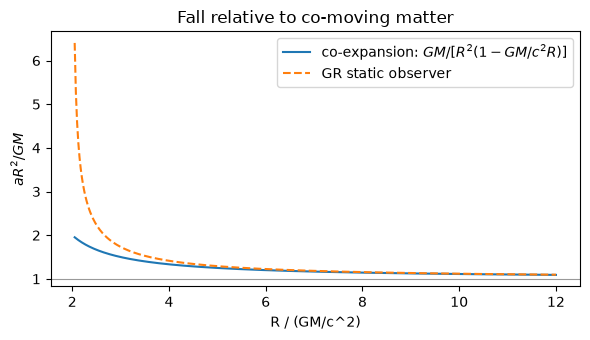

In [31]:
# the fall as relative co-motion, compared with GR's static-observer acceleration (G = c = M = 1, measured radius R)
Rs = np.linspace(2.05, 12, 400)
a_coexp = 1/(Rs**2*(1 - 1/Rs))
a_gr = 1/(Rs**2*np.sqrt(1 - 2/Rs))
plt.figure(figsize=(6, 3.5))
plt.plot(Rs, a_coexp*Rs**2, label="co-expansion: $GM/[R^2(1-GM/c^2R)]$")
plt.plot(Rs, a_gr*Rs**2, "--", label="GR static observer")
plt.axhline(1, color="0.6", lw=0.8)
plt.xlabel("R / (GM/c^2)"); plt.ylabel(r"$a R^2/GM$"); plt.legend(); plt.title("Fall relative to co-moving matter")
plt.tight_layout(); plt.show()

## 7. Self-gravitating bodies: the strong equivalence principle

For a body made of particles (weak field): each particle's weight in the source is $m(1+\Phi/c^2+3v^2/2c^2)$ and its energy is $mc^2+m\Phi+\tfrac12mv^2$. With binding energy $E_g$ and internal kinetic energy $T$:
$$M_g=M+\frac{2E_g+3T}{c^2},\qquad m_i=M+\frac{E_g+T}{c^2}\ \ (\text{field energy } -E_g \text{ included}).$$
A body in equilibrium obeys the virial theorem, $2T+E_g=0$, and then $M_g=m_i=M+E_g/(2c^2)$, as in GR: $\eta_N=0$.

*Pitfall (made and corrected on 2026-11-25):* an unsupported static dust ball ($T=0$) is not in equilibrium and gives $M_g-m_i=E_g/c^2$, i.e. a spurious $\eta_N=1$.

**Status:** the weak equivalence principle (from co-motion along $y$) and the strong one at first order are derived. **Open and testable:** the strong-field value for neutron stars (binding fraction ~0.1–0.2), tested by PSR J0337+1715, $\Delta=(0.5\pm1.8)\times10^{-6}$. It needs the interiors with the full source first (see *Where we are*).

In [32]:
show(r"Source weight", p2.particle_source_weight(), r",\qquad\text{energy}\ ", p2.particle_energy(), sep=" ")
Mg, mi = p2.weak_field_mass_budget()
show(r"$M_g =$", Mg, r",\qquad m_i =", mi, sep=" ")
vir = {T_kinetic: -E_binding/2}
show(r"Equilibrium ($2T + E_g = 0$): $M_g - m_i =$", smp.simplify((Mg - mi).subs(vir)), r",\quad M_g = m_i =", smp.simplify(mi.subs(vir)), sep=" ")
show(r"Pitfall, unsupported dust ($T = 0$): $M_g - m_i =$", smp.simplify((Mg - mi).subs(T_kinetic, 0)))

Source weight $\displaystyle m \left(- \frac{\psi}{2} + 1 + \frac{3 v^{2}}{2 c^{2}}\right) ,\qquad\text{energy}\  - \frac{\psi c^{2} m}{2} + c^{2} m + \frac{m v^{2}}{2}$

$M_g =$ $\displaystyle M + \frac{2 E_{g} + 3 T_{\text{kin}}}{c^{2}} ,\qquad m_i = M + \frac{E_{g} + T_{\text{kin}}}{c^{2}}$

Equilibrium ($2T + E_g = 0$): $M_g - m_i =$ $\displaystyle 0 ,\quad M_g = m_i = \frac{E_{g}}{2 c^{2}} + M$

Pitfall, unsupported dust ($T = 0$): $M_g - m_i =$ $\displaystyle \frac{E_{g}}{c^{2}}$

## 8. Several masses

* $W$ (the flow) plays the role of the **vector potential**: a test body obeys $\dot{\mathbf v}=\nabla(W^2/2)+\partial_t\mathbf W-\mathbf v\times(\nabla\times\mathbf W)$.
* Adding flows like $\mathbf E$ fields ($\mathbf W=\sum\mathbf W_i$) misses Newton by tens of m/s² at the Earth's surface. Drawing $\mathbf W$ along field lines gives Newton but a vorticity ~$10^9$ times Gravity Probe B. Only curl-free (eikonal) flows survive; their divides carry no force, and their position is set by free constants (to-do item 8).
* One induced hypersurface cannot carry two masses (Codazzi fails); co-expansion avoids this because the measured geometry is $\gamma^2|d\mathbf x|^2$ and $\psi$ superposes.

In [33]:
B = ((1.989e30, (0, 0, 0)), (5.972e24, (1.496e11, 0, 0)))   # Sun + Earth (SI)
G_SI, RE = 6.674e-11, 6.371e6
at_surface = {x: 1.496e11, y: RE, z: 0.0}
g_newton = -p2.grad_potential((x, y, z), B, G=G_SI)
a_lin = p2.acceleration_static(p2.flow_linear((x, y, z), B, G=G_SI), (x, y, z))
err_lin = float(smp.sqrt(sum(e**2 for e in (a_lin - g_newton).subs(at_surface))))
W_fl = p2.flow_field_lines((x, y, z), B, G=G_SI)
om = 0.5*float(smp.sqrt(sum(e**2 for e in p2.vorticity(W_fl, (x, y, z)).subs({x: 1.496e11, y: RE + 6.42e5, z: 0.0}))))
nb.printMarkdown(f"""| flow rule | result | data |
|---|---|---|
| linear sum of flows | $|a - g| = {err_lin:.1f}$ m/s² at the Earth's surface | Newton |
| flow along field lines | gyro precession ${om:.2e}$ rad/s at GP-B altitude | $5.7\\times10^{{-15}}$ rad/s |""")

| flow rule | result | data |
|---|---|---|
| linear sum of flows | $|a - g| = 74.0$ m/s² at the Earth's surface | Newton |
| flow along field lines | gyro precession $6.80e-06$ rad/s at GP-B altitude | $5.7\times10^{-15}$ rad/s |

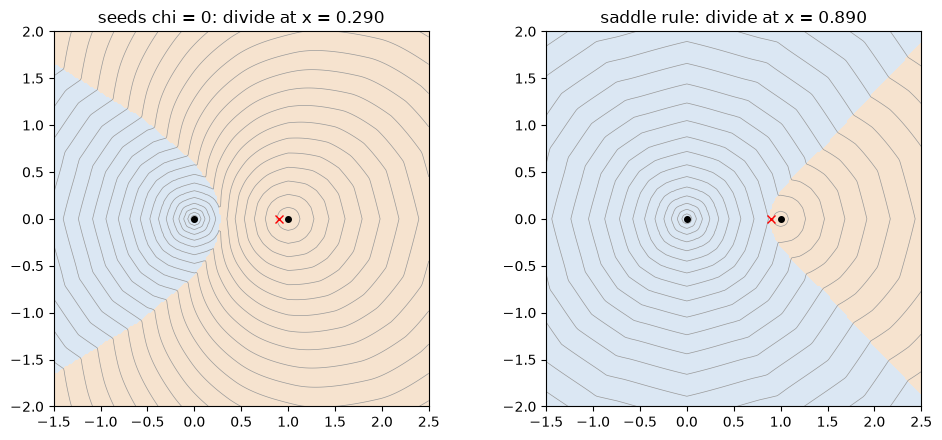

Codazzi residual for two equal masses (median): $0.088$, so no single induced hypersurface carries both.

In [34]:
# eikonal (curl-free) outward flow, Earth-Moon mass ratio: zero seeds vs the saddle rule
bodies = (pf.Body(1.0, (0.0, 0.0, 0.0)), pf.Body(0.0123, (1.0, 0.0, 0.0)))
seed, saddle = pf.saddle_rule_seed(bodies, n=161, iters=11)
fig, axs = plt.subplots(1, 2, figsize=(10, 4.5))
for ax, (title, seeds) in zip(axs, [("seeds chi = 0", [0, 0]), ("saddle rule", [0, seed])]):
    sol = pf.flow_eikonal(bodies, n=201, seeds=seeds)
    X, Y = np.meshgrid(sol["x"], sol["y"], indexing="ij")
    ax.contourf(X, Y, sol["owner"], levels=[-.5, .5, 1.5], colors=["#dbe7f3", "#f6e3cf"])
    ax.contour(X, Y, sol["chi"], levels=20, colors="0.6", linewidths=0.5)
    ax.plot([0, 1], [0, 0], "ko", ms=4); ax.plot([saddle], [0], "rx")
    ax.set_title(f"{title}: divide at x = {pf.divide_on_axis(sol)[0]:.3f}"); ax.set_aspect("equal")
plt.tight_layout(); plt.show()

rng = np.random.default_rng(1)
pts = [p for p in rng.uniform(-2, 3, (80, 3)) if min(np.linalg.norm(p), np.linalg.norm(p - [1, 0, 0])) > 0.2][:30]
two = [v_ for v_ in (pf.codazzi_residual(p) for p in pts) if v_ is not None]
nb.printMarkdown(f"Codazzi residual for two equal masses (median): ${np.median(two):.3f}$, so no single induced hypersurface carries both.")

## 9. Compact objects

With the leading-order interior source ($\sigma\simeq\rho$), a uniform star has a finite central pressure at every compactness (no Buchdahl limit), and its measured surface radius $GM/c^2+\sqrt{(GM/c^2)^2+a^2}$ always exceeds $2GM/c^2$: collapse would end in a horizonless object whose surface approaches the absolute centre. **Superseded by section 10**, which uses the full source $2\rho/(1+\gamma^2)$ with pressure; observational limits on surfaces (Sgr A*) are to-do item 2.

Surface radius $R_s =$ $\displaystyle \frac{G M}{c^{2}} + \sqrt{\frac{G^{2} M^{2}}{c^{4}} + a^{2}} ,\qquad z_s = \frac{G M}{a c^{2}} + \sqrt{\frac{G^{2} M^{2}}{a^{2} c^{4}} + 1} - 1$

| $GM/c^2a$ | $p_c/\epsilon_c$ | centre clock | $R_s/2M$ | $z_s$ |
|---|---|---|---|---|
| 0.01 | 0.0050 | 0.9851 | 50.50250 | 0.010 |
| 0.1 | 0.0549 | 0.8612 | 5.52494 | 0.105 |
| 0.25 | 0.1528 | 0.6930 | 2.56155 | 0.281 |
| 0.5 | 0.3336 | 0.5000 | 1.61803 | 0.618 |
| 1 | 0.6257 | 0.3028 | 1.20711 | 1.414 |
| 2 | 0.8696 | 0.1623 | 1.05902 | 3.236 |
| 5 | 0.9884 | 0.0664 | 1.00990 | 9.099 |
| 20 | 1.0139 | 0.0167 | 1.00062 | 39.025 |
| 100 | 1.0156 | 0.0033 | 1.00002 | 199.005 |

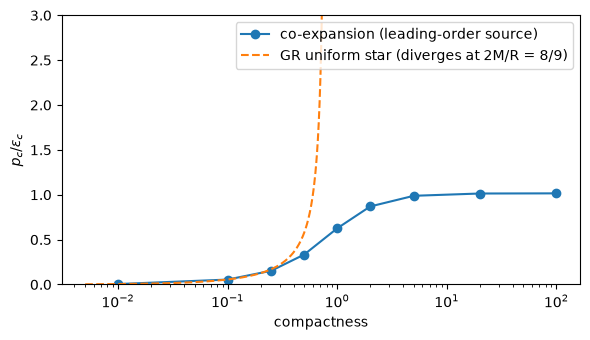

In [35]:
show(r"Surface radius $R_s =$", p2.surface_radius_measured(), r",\qquad z_s =", p2.surface_redshift(), sep=" ")
Cs = [0.01, 0.1, 0.25, 0.5, 1, 2, 5, 20, 100]
rows = [pf.uniform_star(C_) for C_ in Cs]
nb.printMarkdown("| $GM/c^2a$ | $p_c/\\epsilon_c$ | centre clock | $R_s/2M$ | $z_s$ |\n|---|---|---|---|---|\n" + "\n".join(
    f"| {C_} | {s_['pc_over_epsc']:.4f} | {s_['centre_clock']:.4f} | {s_['R_surface_over_2M']:.5f} | {s_['surface_redshift']:.3f} |" for C_, s_ in zip(Cs, rows)))
plt.figure(figsize=(6, 3.5))
plt.semilogx(Cs, [s_["pc_over_epsc"] for s_ in rows], "o-", label="co-expansion (leading-order source)")
xs_ = np.linspace(0.01, 8/9 - 1e-3, 200); s_gr = np.sqrt(1 - xs_)
plt.semilogx(xs_/2/(1 - xs_/2), (1 - s_gr)/(3*s_gr - 1), "--", label="GR uniform star (diverges at 2M/R = 8/9)")
plt.ylim(0, 3); plt.xlabel("compactness"); plt.ylabel(r"$p_c/\epsilon_c$"); plt.legend(); plt.tight_layout(); plt.show()

## 10. Neutron-star interiors and the strong-field equivalence principle

**Interior equations** (static perfect fluid, measured $\epsilon$ and $p$, absolute radius $r$). The static energy at fixed baryon number per absolute volume is
$$E=\frac{c^4}{32\pi G}\int|\nabla\psi|^2d^3x+\int\gamma^2\epsilon\,d^3x .$$
* Varying $\gamma$: $\partial_\gamma(\gamma^2\epsilon)=-\gamma(\epsilon+3p)$, so **pressure gravitates** and
$$\nabla^2\psi=-\frac{16\pi G}{c^4}\,\frac{\gamma^3(\epsilon+3p)}{1+\gamma^2}$$
(dust gives back $2\rho/(1+\gamma^2)$).
* Varying the matter: $dp/dr=(\epsilon+p)\gamma'/\gamma$, so the specific enthalpy is simply $h=\gamma/\gamma_s$.

**Masses.**
* The exterior is the co-expansion solution, with Keplerian (active) mass $Mc^2=\int 2\gamma^3(\epsilon+3p)/(1+\gamma^2)\,d^3x$.
* The force on the star in an external field gives a **passive mass equal to $M$ exactly**.
* A dilation (virial) identity gives $E_{\rm field}=3\int\gamma^2p$, hence a total energy $E=\int\gamma^2(\epsilon+3p)\,d^3x$ (Tolman–Komar form). Therefore
$$E-Mc^2=\int\gamma^2(\epsilon+3p)\,\frac{(\gamma-1)^2}{1+\gamma^2}\,d^3x\;\ge 0 .$$

The gravitational mass is smaller than the inertial mass at **second order** ($\approx u^2/2$). This is not a first-order effect, so it is consistent with $\eta_N=0$ and lunar laser ranging. But a neutron star has $u\sim0.2$.

In [36]:
show(r"Field equation with pressure: $\nabla^2\psi =$", p2.fluid_field_source())
show(r"Keplerian mass density $\rho_K =$", p2.keplerian_mass_density(), r",\qquad\text{energy density}\ ", p2.onshell_energy_density(), sep=" ")
show(r"$E - Mc^2$ integrand:", p2.sep_deficit_density())
gs_ = smp.Symbol(gamma.name, positive=True)
show(r"SEP weight $w =$", p2.sep_weight(gs_), r"\quad\text{weak field: }", smp.series(p2.sep_weight(gs_).subs(gs_, g_sc), u, 0, 3), sep=" ")
show(r"Exponential metric ($\ln\gamma$ harmonic): $w =$", p2.sep_weight(gs_, smp.log(gamma)))
show(r"$e^u - (u + \sqrt{1+u^2}) =$", smp.series(p2.exponential_gamma() - g_sc, u, 0, 5))

Field equation with pressure: $\nabla^2\psi =$ $\displaystyle - \frac{16 \pi G \gamma^{3} \left(\epsilon + 3 p_{0}\right)}{c^{4} \left(\gamma^{2} + 1\right)}$

Keplerian mass density $\rho_K =$ $\displaystyle \frac{2 \gamma \left(\epsilon + 3 p_{0}\right)}{c^{2} \left(1 + \frac{1}{\gamma^{2}}\right)} ,\qquad\text{energy density}\  \gamma^{2} \left(\epsilon + 3 p_{0}\right)$

$E - Mc^2$ integrand: $\displaystyle \frac{\gamma^{2} \left(\epsilon + 3 p_{0}\right) \left(\gamma - 1\right)^{2}}{\gamma^{2} + 1}$

SEP weight $w =$ $\displaystyle \frac{2 \gamma}{\gamma^{2} + 1} \quad\text{weak field: } 1 - \frac{u^{2}}{2} + O\left(u^{3}\right)$

Exponential metric ($\ln\gamma$ harmonic): $w =$ $\displaystyle 1$

$e^u - (u + \sqrt{1+u^2}) =$ $\displaystyle \frac{u^{3}}{6} + \frac{u^{4}}{6} + O\left(u^{5}\right)$

In [37]:
# PSR J0337+1715: pulsar of 1.4378 M_sun; bound |(m_g/m_i)_NS - (m_g/m_i)_WD| = (0.5 +- 1.8) x 1e-6. White-dwarf delta ~ u^2 ~ 1e-10.
rows = []
for eos in (pf.polytrope_eos(100.0, 2.0), pf.polytrope_eos(3000.0, 2.5)):
    s = pf.interior_star_with_mass(pf.J0337_PULSAR_MASS, eos, dr=0.01, iters=16)
    rows.append(f"| co-expansion, {eos.label} | ${s['delta']:+.4f}$ | {abs(s['delta'])/pf.J0337_DELTA[1]:.0f}× | {s['R_km']:.1f} km | {s['binding_fraction']:.3f} |")
x = pf.interior_star(1.3, field="exponential", dr=0.01, iters=40, F_hi=10.0)
rows.append(f"| exponential metric, $M = {x['M']:.3f}$ | ${x['delta']:+.1e}$ | (numerical zero) | | |")
nb.printMarkdown("| star | $M/E - 1$ | vs. 95% bound | radius | binding |\n|---|---|---|---|---|\n" + "\n".join(rows))

| star | $M/E - 1$ | vs. 95% bound | radius | binding |
|---|---|---|---|---|
| co-expansion, polytrope K=100, Gamma=2 | $-0.0396$ | 22010× | 14.5 km | 0.074 |
| co-expansion, polytrope K=3000, Gamma=2.5 | $-0.0472$ | 26219× | 12.4 km | 0.099 |
| exponential metric, $M = 1.404$ | $+1.2e-06$ | (numerical zero) | | |

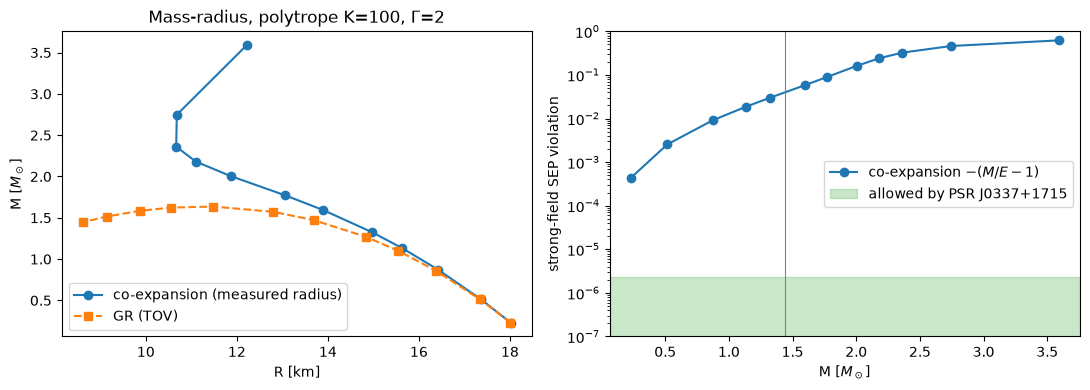

In [38]:
hcs = [1.02, 1.05, 1.1, 1.15, 1.2, 1.3, 1.4, 1.6, 1.8, 2.0, 2.3, 2.6]
seq = [pf.interior_star(h, dr=0.01, iters=40) for h in hcs]
gr = [pf.gr_tov_star(h, dr=0.004) for h in hcs]
fig, axs = plt.subplots(1, 2, figsize=(11, 4))
axs[0].plot([s_["R_km"] for s_ in seq], [s_["M"] for s_ in seq], "o-", label="co-expansion (measured radius)")
axs[0].plot([g_["R_km"] for g_ in gr], [g_["M"] for g_ in gr], "s--", label="GR (TOV)")
axs[0].set_xlabel("R [km]"); axs[0].set_ylabel(r"M [$M_\odot$]"); axs[0].set_title(r"Mass-radius, polytrope K=100, $\Gamma$=2"); axs[0].legend()
axs[1].semilogy([s_["M"] for s_ in seq], [-s_["delta"] for s_ in seq], "o-", label=r"co-expansion $-(M/E-1)$")
axs[1].axhspan(1e-12, 2.3e-6, color="tab:green", alpha=0.25, label="allowed by PSR J0337+1715")
axs[1].axvline(pf.J0337_PULSAR_MASS, color="0.5", lw=0.8)
axs[1].set_xlabel(r"M [$M_\odot$]"); axs[1].set_ylabel("strong-field SEP violation"); axs[1].set_ylim(1e-7, 1); axs[1].legend()
plt.tight_layout(); plt.show()

**What this means.**
* If a star's inertial mass is its total energy $E$, co-expansion as it stands predicts that a neutron star falls about 4% slower than a white dwarf. That holds in any completion where a moving star carries its rest energy as inertia.
* PSR J0337+1715 allows about $2\times10^{-6}$, so this is excluded by roughly $2\times10^4$.
* The result does not depend on the equation of state: the violation is $\approx u^2/2$ weighted over the star.

**Why it happens.** Take any single field $F(\gamma)$ that is harmonic outside matter, has a quadratic gradient energy, and couples matter to the co-expansion geometry. In that class the masses agree exactly **only** for $F=\ln\gamma$, i.e. the exponential metric $\gamma=e^{GM/c^2r}$. The co-expansion rule (flow set by the measured radius) makes $\psi=\gamma-1/\gamma$ harmonic instead. The two agree through $u^2$ and differ first at $u^3$, the second post-Newtonian order where this theory departs from GR.

**Ways forward (author's decision):**
* **(A)** Keep the measured-radius rule. Then the time-dependent sector (to-do item 3) must give a moving star an inertial mass equal to $M$, not $E$, to $10^{-6}$. That is a sharp requirement on item 3.
* **(B)** Make $\ln\gamma$ the harmonic field. This keeps co-motion along $y$, the co-expansion form of the metric, PPN $\gamma=\beta=1$, and gives exact strong equivalence. The flow rule changes at third order: $\beta^2=1-e^{-2u}$ instead of $2u/\gamma$.
* **(C)** A field action outside this class (more than one field, non-quadratic, or tensor). This belongs to item 3.

**Interiors with the full source.**
* The polytrope sequence has finite pressure and no maximum mass up to the end of the sequence we found ($h_c\approx2.9$).
* Every star is horizonless ($R>2M$).
* Binding is very large near the end of the sequence. Stability has not been checked yet.

## 11. Time-dependent equations under option A: first results

What option A needs from the time-dependent theory:
1. Its static limit is sections 5–10.
2. A moving star has inertial mass $M$ (Keplerian), not $E$, to $10^{-6}$ (PSR J0337+1715).
3. At first order, moving sources give GR's metric, so the preferred-frame parameters vanish ($|\alpha_1|\lesssim10^{-5}$, $|\alpha_2|\lesssim10^{-9}$).
4. Radiation is tensor, travels at $c$ (GW170817), and follows the quadrupole formula (binary pulsars).

**(i) A preferred frame is unavoidable.**
* In covariant form the matter metric is $g=\gamma^2\eta+(\gamma^2-\gamma^{-2})\,u\,u$, with $u$ the absolute frame. This is natural for absolute time.
* Requirement 2 also forces a preferred frame. In any Lorentz- or diffeomorphism-invariant completion a moving star has momentum $P=EV$, i.e. $m_i=E$, which would bring back the 4% violation.

**(ii) The metric alone cannot carry co-expansion.**
* Take absolute time as a preferred slicing with unit lapse (paper one's flow form). The most general two-derivative action for the slices and the flow is $\int\sqrt h\,[K_{ij}K^{ij}-\lambda K^2+\xi R]$.
* With $\lambda=\xi=1$ it reproduces GR's Painlevé–Gullstrand solution exactly.
* For the co-expansion geometry, first order forces $\lambda=1$. Then the momentum constraint fails at $O(M^{5/2})$ for every $\xi$. So the theory needs a field beyond the metric: naturally $\psi$, i.e. the height $y$.

**(iii) That field looks like a ghost.** Read through the Einstein equations, its stress at leading order is that of a negative-energy scalar: $\rho=p_r=-g^2/8\pi G$, $p_t=-p_r$. Negative-energy fields that interact with ordinary ones are usually unstable. That is the central question for option A.

In [39]:
show(r"Covariant matter metric $g_{\mu\nu} =$", p2.covariant_matter_metric())
Mq, rq = (smp.Symbol(s_.name, positive=True) for s_ in (M, r))
res_A = p2.foliation_residuals(p2.gamma_self_consistent(Mq/rq), Mq, rq)
for name, e in zip(("Momentum constraint", "$h_{rr}$ equation", "Angular $h$ equation"), res_A):
    show(f"{name}:", smp.collect(e, Mq))
show(r"With $\lambda = 1$, momentum constraint:", smp.simplify(res_A[0].subs(p2.foliation_residuals.__defaults__[3], 1)))

Covariant matter metric $g_{\mu\nu} =$ $\displaystyle Matrix([[-1/\gamma**2, 0, 0, 0], [0, \gamma**2, 0, 0], [0, 0, \gamma**2, 0], [0, 0, 0, \gamma**2]])$

Momentum constraint: $\displaystyle M^{\frac{7}{2}} \left(- \frac{33 \sqrt{2} \lambda_{K}}{32 r^{\frac{7}{2}}} + \frac{97 \sqrt{2}}{32 r^{\frac{7}{2}}}\right) + M^{\frac{5}{2}} \left(\frac{111 \sqrt{2} \lambda_{K}}{16 r^{\frac{5}{2}}} - \frac{47 \sqrt{2}}{16 r^{\frac{5}{2}}}\right) + M^{\frac{3}{2}} \left(\frac{9 \sqrt{2} \lambda_{K}}{4 r^{\frac{3}{2}}} - \frac{9 \sqrt{2}}{4 r^{\frac{3}{2}}}\right) + \sqrt{M} \left(- \frac{9 \sqrt{2} \lambda_{K}}{2 \sqrt{r}} + \frac{9 \sqrt{2}}{2 \sqrt{r}}\right)$

$h_{rr}$ equation: $\displaystyle M^{3} \left(- \frac{9 \lambda_{K}}{4 r^{3}} + \frac{9}{4 r^{3}}\right) + M^{2} \left(- \frac{9 \lambda_{K}}{2 r^{2}} + \frac{2 \xi_{R}}{r^{2}} + \frac{9}{2 r^{2}}\right) + M \left(\frac{9 \lambda_{K}}{2 r} - \frac{9}{2 r}\right)$

Angular $h$ equation: $\displaystyle M^{3} \left(\frac{3 \lambda_{K}}{r^{4}} + \frac{1}{r^{4}}\right) + M^{2} \left(\frac{18 \lambda_{K}}{r^{3}} - \frac{4 \xi_{R}}{r^{3}} - \frac{18}{r^{3}}\right) + M \left(- \frac{9 \lambda_{K}}{r^{2}} + \frac{9}{r^{2}}\right)$

With $\lambda = 1$, momentum constraint: $\displaystyle \frac{2 \sqrt{2} M^{\frac{5}{2}} \left(M + 2 r\right)}{r^{\frac{7}{2}}}$

### 11b. How moving matter drags the flow (first order)

**Picture.** $\psi$ is set instantaneously on each absolute slice. In the author's words, the temporal surface moves out with the Earth; it is not a wave. A mass moving through the absolute frame also *drags the flow* along: the flow picks up a component $-\mathbf w$, where $w_i=g_{0i}$.

**Equation.** Co-expansion forced $\lambda=1$ at first order (11), so at first order the flow obeys the linearised momentum constraint $R_{0i}=8\pi T_{0i}$. In the absolute frame its solution is
$$\mathbf w=-4\mathbf V+\tfrac12\nabla\dot\chi=-\tfrac72\mathbf V-\tfrac12\mathbf W,\qquad \nabla^2\mathbf V=-4\pi\rho\mathbf v,\quad \nabla^2\chi=-2U .$$
Moving matter drags the flow by four times its momentum potential, plus a longitudinal part set by $\dot U$.

**How it aligns.**
* The static sector, with $\psi$'s source weights, already gives GR's $g_{00}$ through first order.
* With the flow response, **every PPN parameter equals GR's**, including the preferred-frame ones: $\alpha_1=\alpha_2=\alpha_3=0$, even though there is an absolute frame. Without the response, $\alpha_1=-8$.
* A spinning body drags the flow as $\mathbf w=-2\,\mathbf J\times\mathbf r/r^3$, which is exactly GR's frame dragging (Gravity Probe B: measured $37.2\pm7.2$ mas/yr, predicted 39.2; LAGEOS).
* At first order a moving body's inertial mass is its energy, which equals $M$ at this order: consistent with lunar laser ranging.

**Still open.** These are first-order results only. Option A's real test is at second order: the nonlinear flow equation must give a moving neutron star inertial mass $M$ rather than $E$ (section 10), and it must also cure the $O(M^{5/2})$ failure of the static flow (11). Both are corrections to the same flow equation.

In [40]:
U_, V_, W_, rho_, rhov_ = p2.moving_matter_potentials()
show(r"$R_{0i} + 8\pi\rho v_i =$", smp.simplify(p2.linearized_R0i() + 8*smp.pi*rhov_).T)
show(r"First-PN $g_{00} =$", p2.g00_first_pn())
show(r"Spinning body: $\mathbf w =$", p2.lense_thirring_flow().T, r",\qquad \boldsymbol\Omega =", p2.gyro_precession().T, sep=" ")
show_report(p2.check_flow_response())

$R_{0i} + 8\pi\rho v_i =$ $\displaystyle \left[\begin{matrix}0 & 0 & 0\end{matrix}\right]$

First-PN $g_{00} =$ $\displaystyle - 2 U_{\mathrm{PPN}}^{2} \varepsilon_{\mathrm{PN}}^{2} + 2 U_{\mathrm{PPN}} \varepsilon_{\mathrm{PN}} + 4 \Phi_{1} \varepsilon_{\mathrm{PN}}^{2} + 4 \Phi_{2} \varepsilon_{\mathrm{PN}}^{2} - 1$

Spinning body: $\mathbf w =$ $\displaystyle Matrix([[-2*(J_{y}*z - J_{z}*y)/(x**2 + y**2 + z**2)**(3/2), -2*(-J_{x}*z + J_{z}*x)/(x**2 + y**2 + z**2)**(3/2), -2*(J_{x}*y - J_{y}*x)/(x**2 + y**2 + z**2)**(3/2)]]) ,\qquad \boldsymbol\Omega = Matrix([[2*J_{x}/(x**2 + y**2 + z**2)**(3/2) - 3*y*(J_{x}*y - J_{y}*x)/(x**2 + y**2 + z**2)**(5/2) + 3*z*(-J_{x}*z + J_{z}*x)/(x**2 + y**2 + z**2)**(5/2), 2*J_{y}/(x**2 + y**2 + z**2)**(3/2) + 3*x*(J_{x}*y - J_{y}*x)/(x**2 + y**2 + z**2)**(5/2) - 3*z*(J_{y}*z - J_{z}*y)/(x**2 + y**2 + z**2)**(5/2), 2*J_{z}/(x**2 + y**2 + z**2)**(3/2) - 3*x*(-J_{x}*z + J_{z}*x)/(x**2 + y**2 + z**2)**(5/2) + 3*y*(J_{y}*z - J_{z}*y)/(x**2 + y**2 + z**2)**(5/2)]])$

**flow_response**: 9/9 checks pass

| | check |
|---|---|
| ✅ | continuity holds identically for the constructed moving matter |
| ✅ | w = -4V + (1/2) grad(dchi/dt) (same as -(7/2)V - (1/2)W) |
| ✅ | flow equation: R_0i = 8 pi T_0i = -8 pi rho v_i for arbitrary moving matter |
| ✅ | flow divergence: div w = 3 dU/dt |
| ✅ | static sector: g_00 = GR's -1 + 2U - 2U^2 + 4 Phi_1 + 4 Phi_2 (standard PPN gauge) |
| ✅ | with the flow response every PPN parameter is GR's: alpha_1 = alpha_2 = alpha_3 = zeta_1 = zeta_2 = xi = 0 |
| ✅ | without the flow response (w = 0): alpha_1 = -8 (excluded; |alpha_1| < 1e-4) |
| ✅ | spinning body: w = -2 (J x r)/r^3, GR's Lense-Thirring g_0i |
| ✅ | gyroscope precession Omega = [3(J.n)n - J]/r^3 (GR; Gravity Probe B 37.2 +- 7.2 mas/yr vs 39.2 predicted) |

### 11c. Which slicing is absolute time?

**Author (2026-11-25).**
* Around one uniform spherical body, absolute time is constant on each sphere $R=$ const.
* How one body's "now" relates to another's (Earth and Moon) is unresolved.
* One option, an assumption rather than a fact: the surfaces of the bodies are simultaneous.

**Two separate questions.**
1. *Inter-body synchronization.* This fixes one constant per body: the free "seeds" of section 8. The surface-simultaneity rule is a candidate rule for them. A constant shift of one body's absolute time changes no local equation, so it decides the shape of the slicing *between* bodies (where the flow divides lie), not the single-body physics.
2. *Radial tilt of "now" around one body.* Both candidates keep each sphere simultaneous; they differ in how "now" at $R$ relates to "now" at $R'$:
   * the flow form $T$: unit lapse, outward flow;
   * the static form $t$: lapse $1/\gamma$, no flow.

**Result for the static form.**
* The most general two-derivative action of a preferred slicing reduces, for static fields, to $\int\sqrt h\,N\,[R+\alpha\,a_ia^i]$, with $a_i=\partial_i\ln N$ the "acceleration of absolute time".
* The co-expansion geometry is an **exact vacuum solution at $\alpha=2$**, to all orders. The negative-energy stress is then the energy of the slicing itself, which fits the author's reading.
* With matter, the lapse equation becomes $(1-\alpha/2)\nabla^2\phi=4\pi G\rho$, so at exactly $\alpha=2$ matter drops out.

So the geometry outside a body comes from the absolute-time action, but what ties it to the body's mass must be $\psi$'s own equation, $\nabla^2\psi=-8\pi G\sigma$. **Next:** combine the two consistently. Then (a) re-derive the flow response in this slicing (11b assumed the linearised momentum constraint), and (b) compute a moving star's inertial mass.

In [41]:
res_s = p2.static_foliation_residuals(p2.gamma_self_consistent(Mq/rq), rq)
show(r"Static-slicing vacuum equations on co-expansion:", *res_s, sep=r",\\ ")
show(r"At $\alpha = 2$:", *[smp.simplify(e.subs(p2.static_foliation_residuals.__defaults__[2], 2)) for e in res_s], sep=r",\ ")
show(r"Newtonian coupling factor:", p2.newtonian_coupling_factor())

Static-slicing vacuum equations on co-expansion: $\displaystyle \frac{M^{2} \left(- M^{3} \alpha_{a} + 2 M^{3} - M^{2} \alpha_{a} \sqrt{M^{2} + r^{2}} + 2 M^{2} \sqrt{M^{2} + r^{2}} - M \alpha_{a} r^{2} + 2 M r^{2} + \alpha_{a} r^{2} \sqrt{M^{2} + r^{2}} - 2 r^{2} \sqrt{M^{2} + r^{2}}\right)}{r \left(M^{4} + 2 M^{2} r^{2} + r^{4}\right)},\\ \frac{2 M^{2} \left(M^{2} \alpha_{a} - 2 M^{2} + M \alpha_{a} \sqrt{M^{2} + r^{2}} - 2 M \sqrt{M^{2} + r^{2}} + \alpha_{a} r^{2} - 2 r^{2}\right)}{2 M^{5} + 2 M^{4} \sqrt{M^{2} + r^{2}} + 4 M^{3} r^{2} + 3 M^{2} r^{2} \sqrt{M^{2} + r^{2}} + 2 M r^{4} + r^{4} \sqrt{M^{2} + r^{2}}},\\ \frac{M^{2} r \left(- M \alpha_{a} + 2 M - \alpha_{a} \sqrt{M^{2} + r^{2}} + 2 \sqrt{M^{2} + r^{2}}\right)}{2 M^{4} + 2 M^{3} \sqrt{M^{2} + r^{2}} + 3 M^{2} r^{2} + 2 M r^{2} \sqrt{M^{2} + r^{2}} + r^{4}}$

At $\alpha = 2$: $\displaystyle 0,\ 0,\ 0$

Newtonian coupling factor: $\displaystyle \frac{1}{1 - \frac{\alpha_{a}}{2}}$

### 11d. The combined theory: absolute-time action + $\psi$

**Theory.**
* Absolute time is the static slicing.
* The metric is built from $\psi$, the flow and tensor waves: $N=1/\gamma(\psi)$, $h_{ij}=\gamma^2(\delta_{ij}+h^{TT}_{ij})$, shift $N_i$ free. Matter moves on that metric.
* The action:
$$S=\frac{1}{16\pi G_b}\int\sqrt h\,N\big[K_{ij}K^{ij}-\lambda K^2+R+\alpha\,a_ia^i\big]-\frac{c^4}{32\pi G}\int|\nabla\psi|^2+S_{\rm matter}.$$

**What fixes the coefficients.**
* **$\alpha=2$.** On the co-expansion form, the static part of the absolute-time action is $-4\nabla^2\ln\gamma+(\alpha-2)|\nabla\ln\gamma|^2$ for *any* $\gamma(x)$. That is a pure boundary term iff $\alpha=2$. So the static sector is $\psi$'s alone and every static result (sections 5–10) stands. This also explains 11c: matter "drops out" of the slicing's lapse equation because $\psi$ carries the source.
* **$\lambda=1$.** The flow equation becomes $\nabla^2\dot\zeta=4\pi G_b\,\nabla\!\cdot\!\mathbf J$ ($\zeta=\ln\gamma$). That is exactly the time derivative of $\psi$'s equation plus mass conservation. So $\psi$ **is instantaneous**, set on each slice as in the author's picture, with no scalar waves. For $\lambda\ne1$ the scalar propagates, $c_s^2=(G_b/G)(1-\lambda)/(1-3\lambda)$.
* **$G_b=G$.** The two equations agree only then.
* **$\xi=1$ and no $\beta$ term.** Tensor waves travel at $c$, as in GR (GW170817).

**Consequences at linear order.**
* The longitudinal flow satisfies $\nabla\!\cdot\!\mathbf w=3\dot U$, and the transverse flow $\nabla^2\mathbf S=16\pi G\,\mathbf J^T$, i.e. $\mathbf w^T=-4\mathbf V^T$.
* That is exactly 11b's flow response, which is now **derived rather than assumed**. So the PPN parameters equal GR's and frame dragging equals GR's.

**Next.**
* (a) Second order: are the constraints still consistent with each other, and does the flow form's $O(M^{5/2})$ problem disappear in this slicing?
* (b) The inertial mass of a moving neutron star (target $M$, PSR J0337+1715).

In [42]:
from physics.symbolic.variables import Omega_log, alpha_a
show(r"Static part of the absolute-time action on the co-expansion form:", smp.expand(p2.static_density_on_ansatz(Omega_log, alpha_a)))
show(r"Scalar sound speed squared: $c_s^2 =$", p2.scalar_sound_speed_squared())
show_report(p2.check_combined_theory())

Static part of the absolute-time action on the co-expansion form: $\displaystyle \alpha_{a} \left(\frac{\partial}{\partial x} \Omega{\left(x,y,z \right)}\right)^{2} + \alpha_{a} \left(\frac{\partial}{\partial y} \Omega{\left(x,y,z \right)}\right)^{2} + \alpha_{a} \left(\frac{\partial}{\partial z} \Omega{\left(x,y,z \right)}\right)^{2} - 2 \left(\frac{\partial}{\partial x} \Omega{\left(x,y,z \right)}\right)^{2} - 4 \frac{\partial^{2}}{\partial x^{2}} \Omega{\left(x,y,z \right)} - 2 \left(\frac{\partial}{\partial y} \Omega{\left(x,y,z \right)}\right)^{2} - 4 \frac{\partial^{2}}{\partial y^{2}} \Omega{\left(x,y,z \right)} - 2 \left(\frac{\partial}{\partial z} \Omega{\left(x,y,z \right)}\right)^{2} - 4 \frac{\partial^{2}}{\partial z^{2}} \Omega{\left(x,y,z \right)}$

Scalar sound speed squared: $c_s^2 =$ $\displaystyle \frac{G_{b} \left(1 - \lambda_{K}\right)}{G \left(1 - 3 \lambda_{K}\right)}$

**combined_theory**: 7/7 checks pass

| | check |
|---|---|
| ✅ | static part on the ansatz = -4 lap ln gamma + (alpha - 2)|grad ln gamma|^2 for any gamma(x) |
| ✅ | static limit of the zeta equation: lap zeta = -4 pi G rho (psi = 2U) |
| ✅ | lambda = 1 flow equation: lap(dzeta/dt) = 4 pi G_b div J |
| ✅ | consistent with psi's equation + mass conservation only if G_b = G |
| ✅ | with psi instantaneous the remaining zeta terms vanish iff lap(dB/dt) = 3 d^2zeta/dt^2 (div w = 3 dU/dt) |
| ✅ | transverse flow: curl(lap S - 16 pi G_b J) = 0, i.e. w^T = -4 V^T (frame dragging, as 11b) |
| ✅ | scalar mode: c_s^2 = (G_b/G)(1 - lambda)/(1 - 3 lambda); no scalar waves at lambda = 1 |

### 11e. Second order: a star moving through the absolute frame

**Setup.**
* Move a static star at velocity $V$. To $O(V)$ its fields are the translated static ones plus a flow.
* With $\mathbf W=\mathbf V+\mathbf N$ the flow relative to the matter, the inertia comes from
$$L_2[\mathbf W]=\int\tfrac12\tfrac{\sqrt h}{N}(\epsilon+p)|\mathbf W|^2+\tfrac1{16\pi G}\sqrt hN\,(K_{ij}K^{ij}-K^2),\qquad K_{ij}=-\tfrac{D_iW_j+D_jW_i}{2N},$$
* with $m_i=2L_2/V^2$ and $\mathbf W\to\mathbf V$ far away (the absolute frame at rest there). This is exact in the star's own gravity.
* For $\mathbf W=F(r)\mathbf V+H(r)(\mathbf n\!\cdot\!\mathbf V)\mathbf n$ it reduces to radial equations: $H$ is algebraic, and $F$ obeys a second-order equation.

**Result.**
* **GR:** uniform motion $F=1$ is an exact solution outside the star, as boost invariance requires.
* **Co-expansion:** $F=1$ is *not* a solution; the residual is $2M^2/(3r^2)$. The longitudinal part of the flow is undetermined at orders $M^0$ and $M^1$, and fixed at $M^2$, which is exactly where co-expansion departs from GR. The only far-field solutions are $F\sim r^2$ and $F\sim1/r$.

So in the combined theory **a star cannot move uniformly relative to a distant absolute frame.** Either it carries its absolute frame with it ($F\to0$), or the flow grows as $r^2$ and the inertia diverges.

**Reading.** This matches the author's remark (11c) that absolute time is defined *around each body* ($R=$ const), with the relation between bodies unresolved: here each body's absolute frame moves with the body. Then the inertial mass, and option A's test, cannot be posed until the rule connecting different bodies' frames is known (to-do item 8). The theory also departs sharply from GR here: in GR any body can move through any slicing.

In [43]:
co_g = M/r + smp.sqrt(1 + M**2/r**2)
show(r"GR exterior, residual of uniform motion ($F = 1$):", p2.uniform_motion_residual())
show(r"Co-expansion exterior, residual of uniform motion:", smp.series(p2.uniform_motion_residual(co_g, 1/co_g), M, 0, 3))
show(r"Co-expansion far-field modes $F = r^k$ (leading residual):", p2.far_field_power_modes(co_g, 1/co_g))

GR exterior, residual of uniform motion ($F = 1$): $\displaystyle 0$

Co-expansion exterior, residual of uniform motion: $\displaystyle \frac{2 M^{2}}{3 r^{2}} + O\left(M^{3}\right)$

Co-expansion far-field modes $F = r^k$ (leading residual): $\displaystyle - \frac{M^{2} w_{far}^{2} \left(k_{p} - 2\right) \left(k_{p} + 1\right)}{3}$

## 12. All consistency checks

In [44]:
reports = [chk() for chk in (p2.check_flow_geometry, p2.check_newtonian_flow, p2.check_y_field, p2.check_absolute_time_matter, pf.check_paper_two_absolute_time, p2.check_co_expansion, p2.check_co_expansion_field, p2.check_co_expansion_action,
            p2.check_flow_superposition, p2.check_compact_objects, p2.check_stellar_structure, p2.check_time_dependent,
            p2.check_flow_response, p2.check_static_foliation, p2.check_combined_theory, p2.check_moving_star,
            pf.check_paper_two_numeric, pf.check_paper_two_stellar)]
nb.printMarkdown("| suite | passed |\n|---|---|\n" + "\n".join(
    f"| `{rep.title}` | {sum(1 for row in rep.rows if row[1])}/{len(rep.rows)} {'✅' if all(row[1] for row in rep.rows) else '❌'} |" for rep in reports))

| suite | passed |
|---|---|
| `co_expansion` | 27/27 ✅ |
| `co_expansion_field` | 13/13 ✅ |
| `co_expansion_action` | 8/8 ✅ |
| `flow_superposition` | 6/6 ✅ |
| `compact_objects` | 6/6 ✅ |
| `stellar_structure` | 13/13 ✅ |
| `time_dependent` | 6/6 ✅ |
| `flow_response` | 9/9 ✅ |
| `static_foliation` | 4/4 ✅ |
| `combined_theory` | 7/7 ✅ |
| `moving_star` | 5/5 ✅ |
| `paper_two_numeric` | 8/8 ✅ |
| `paper_two_stellar` | 9/9 ✅ |

## 13. Open items

See `../todo.md`. In order:
1. **Time-dependent field equations under option A** (section 11): a metric plus the field $\psi$ (or $y$) on the absolute slicing. It must give $m_i=M$, no first-order preferred-frame effects, and GR's quadrupole radiation. First question: is the $\psi$ sector a ghost (unstable)?
2. Stability of the interior sequence; realistic neutron-star equations of state (item 4).
3. Horizonless surfaces against observations (Sgr A*, M87*).
4. Time-dependent field equations with a tensor sector (binary pulsars, GW polarizations); a scalar alone fails. Under option A this must also fix the inertial mass.
5. Cosmic co-expansion and $\dot G/G$; 6. rotation from the field equation; 7. the ringdown properly; 8. the direction of the flow between masses; 9. time of a body at rest.